In [ ]:
from skimage.exposure import rescale_intensity
import matplotlib.pyplot as plt
import numpy as np
import cv2

In [ ]:
image = cv2.imread("/content/jemma.png")
def plt_imshow(title, image):
    # convert the image frame BGR to RGB color space and display it
    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.imshow(image)
    plt.title("Image")
    plt.grid(False)
    plt.show()

In [ ]:
def convolve(image, K):
	# grab the spatial dimensions of the image and kernel
	(iH, iW) = image.shape[:2]
	(kH, kW) = K.shape[:2]

	# allocate memory for the output image, taking care to "pad"
	# the orders of the input image so the spatial size (i.e.,
	# width and height) are not reduced
	pad = (kW - 1) // 2
	image = cv2.copyMakeBorder(image, pad, pad, pad, pad,
		cv2.BORDER_REPLICATE)
	output = np.zeros((iH, iW), dtype="float")

	# loop over the input image, "sliding" the kernel across
	# each (x, y)-coordinate from left-to-right and top-to-bottom
	for y in np.arange(pad, iH + pad):
		for x in np.arange(pad, iW + pad):
			# extract the ROI of the image by extracting the
			# *center* region of the current (x, y)-coordinates
			# dimensions
			roi = image[y - pad:y + pad + 1, x - pad:x + pad + 1]

			# perform the actual convolution by taking the
			# element-wise multiplication between the ROI and
			# the kernel, the summing the matrix
			k = (roi * K).sum()

			# store the convolved value in the output (x, y)-
			# coordinate of the output image
			output[y - pad, x - pad] = k

	# rescale the output image to be in the range [0, 255]
	output = rescale_intensity(output, in_range=(0, 255))
	output = (output * 255).astype("uint8")

	# return the output image
	return output

[INFO] applying small_blur kernel


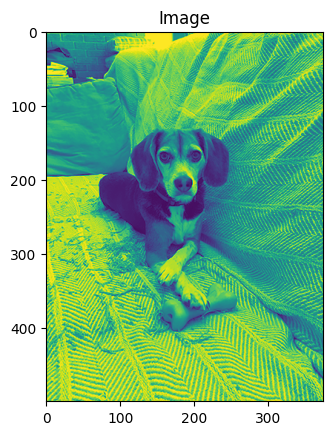

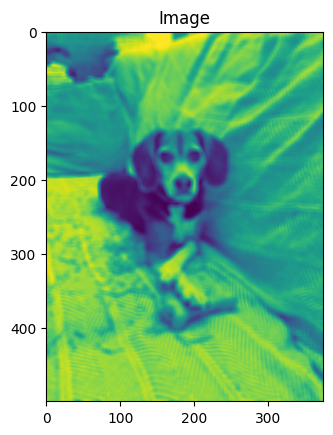

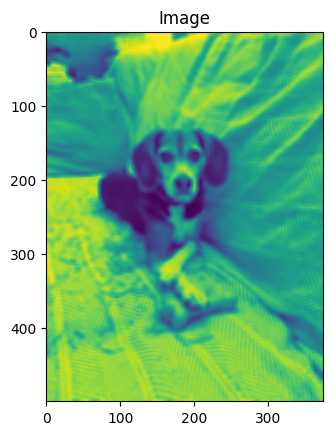

[INFO] applying large_blur kernel


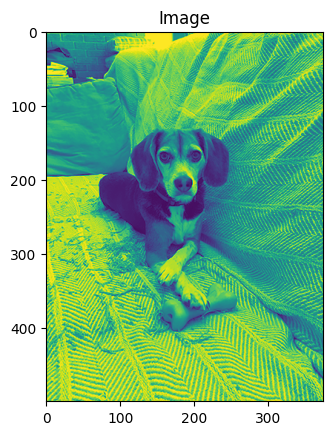

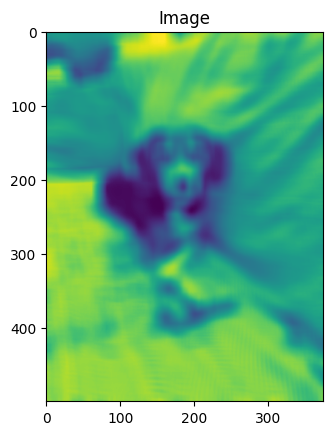

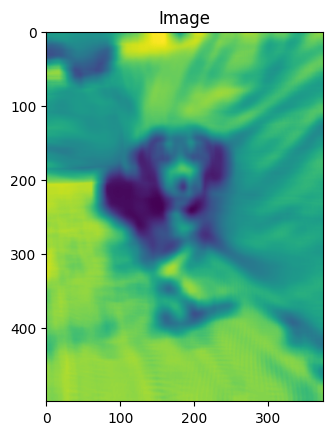

[INFO] applying sharpen kernel


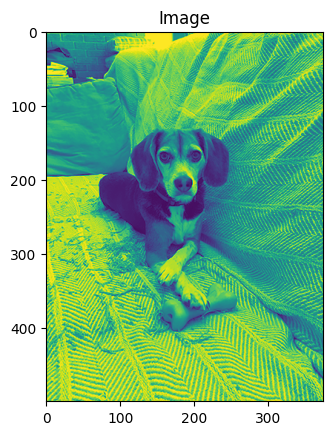

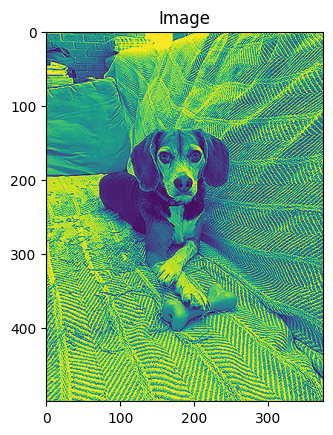

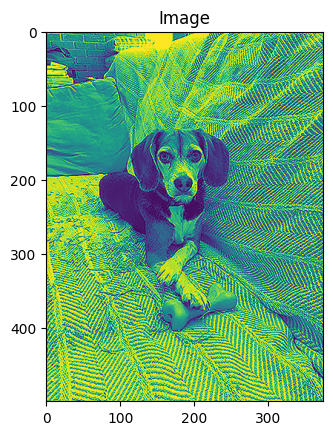

[INFO] applying laplacian kernel


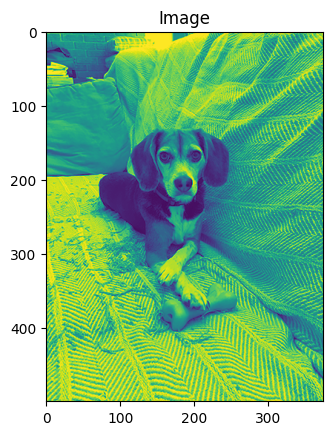

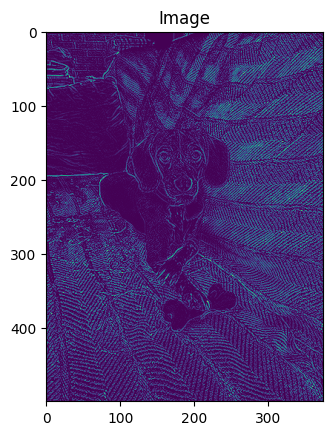

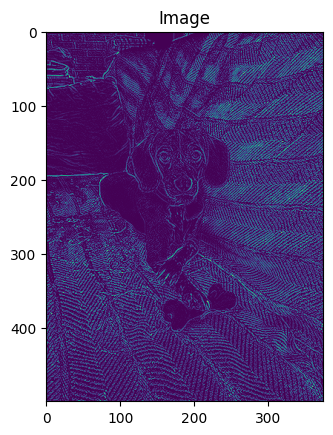

[INFO] applying sobel_x kernel


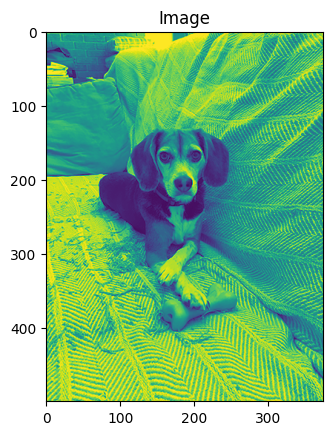

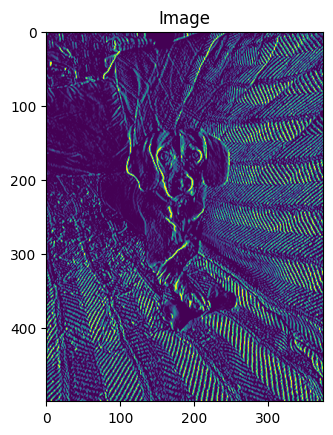

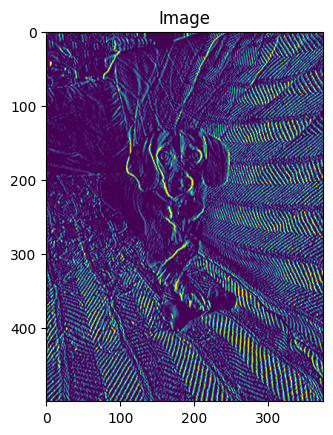

[INFO] applying sobel_y kernel


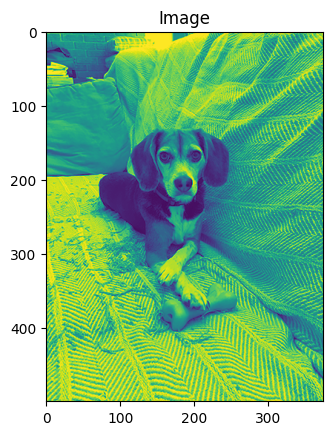

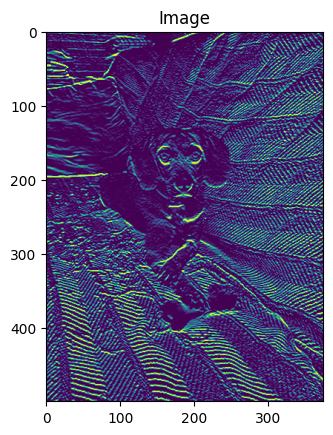

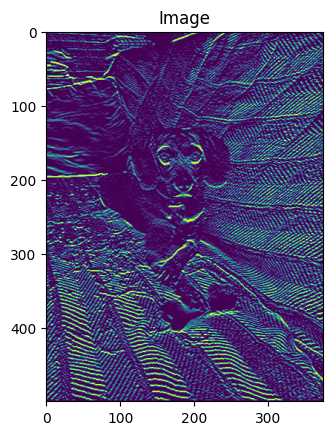

[INFO] applying emboss kernel


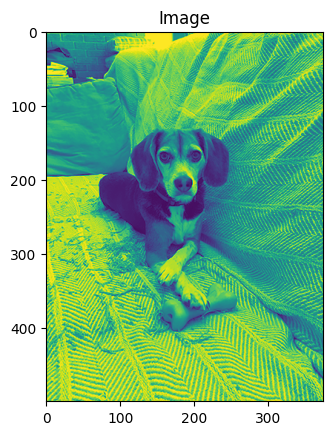

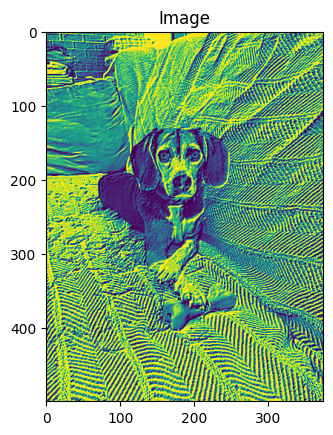

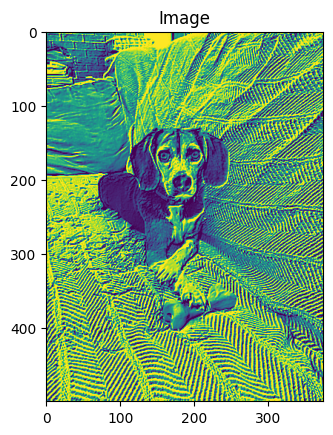

In [ ]:
# construct average blurring kernels used to smooth an image
smallBlur = np.ones((7, 7), dtype="float") * (1.0 / (7 * 7))
largeBlur = np.ones((21, 21), dtype="float") * (1.0 / (21 * 21))
# construct a sharpening filter
sharpen = np.array((
	[0, -1, 0],
	[-1, 5, -1],
	[0, -1, 0]), dtype="int")
# construct the Laplacian kernel used to detect edge-like
# regions of an image
laplacian = np.array((
	[0, 1, 0],
	[1, -4, 1],
	[0, 1, 0]), dtype="int")
# construct the Sobel x-axis kernel
sobelX = np.array((
	[-1, 0, 1],
	[-2, 0, 2],
	[-1, 0, 1]), dtype="int")
# construct the Sobel y-axis kernel
sobelY = np.array((
	[-1, -2, -1],
	[0, 0, 0],
	[1, 2, 1]), dtype="int")
# construct an emboss kernel
emboss = np.array((
	[-2, -1, 0],
	[-1, 1, 1],
	[0, 1, 2]), dtype="int")
# construct the kernel bank, a list of kernels we're going to apply
# using both our custom `convole` function and OpenCV's `filter2D`
# function
kernelBank = (
	("small_blur", smallBlur),
	("large_blur", largeBlur),
	("sharpen", sharpen),
	("laplacian", laplacian),
	("sobel_x", sobelX),
	("sobel_y", sobelY),
	("emboss", emboss))
# load the input image and convert it to grayscale
image = cv2.imread("jemma.png")
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
# loop over the kernels
for (kernelName, K) in kernelBank:
	# apply the kernel to the grayscale image using both our custom
	# `convolve` function and OpenCV's `filter2D` function
	print("[INFO] applying {} kernel".format(kernelName))
	convolveOutput = convolve(gray, K)
	opencvOutput = cv2.filter2D(gray, -1, K)

	# show the output images
	plt_imshow("Original", gray)
	plt_imshow("{} - convole".format(kernelName), convolveOutput)
	plt_imshow("{} - opencv".format(kernelName), opencvOutput)

In [ ]:
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # The CIFAR labels happen to be arrays,
    # which is why you need the extra index
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.summary()
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))
model.summary()
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

history = model.fit(train_images, train_labels, epochs=10,
                    validation_data=(test_images, test_labels))
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)
print(test_acc)

170498071/170498071 [==============================] - 6s 0us/step


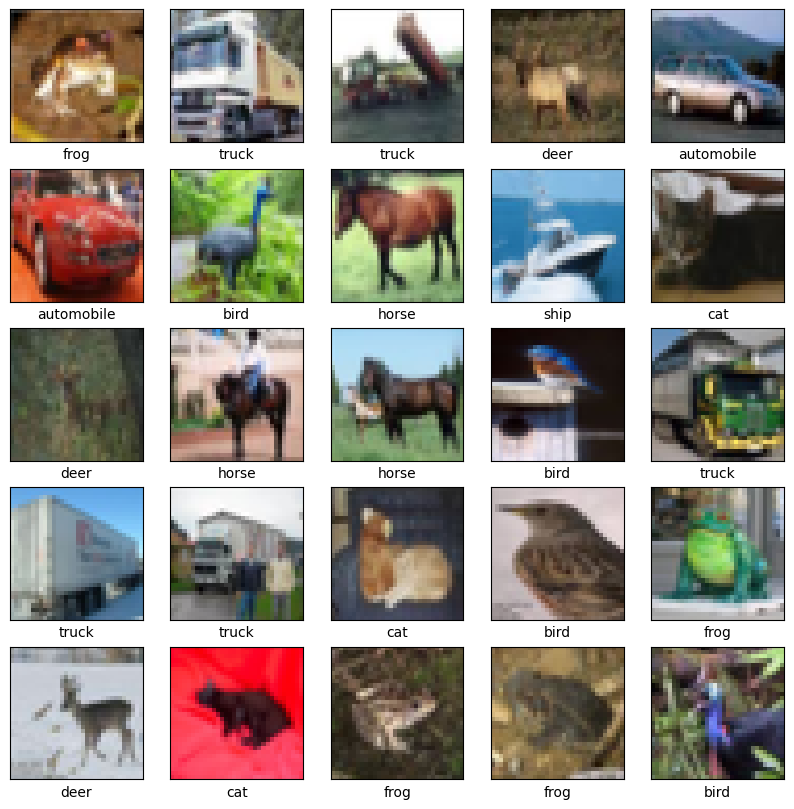

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 30, 30, 32)        896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 15, 15, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 13, 13, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 6, 6, 64)          0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 4, 4, 64)          36928     
                                                                 
Total params: 56320 (220.00 KB)
Trainable params: 56320 

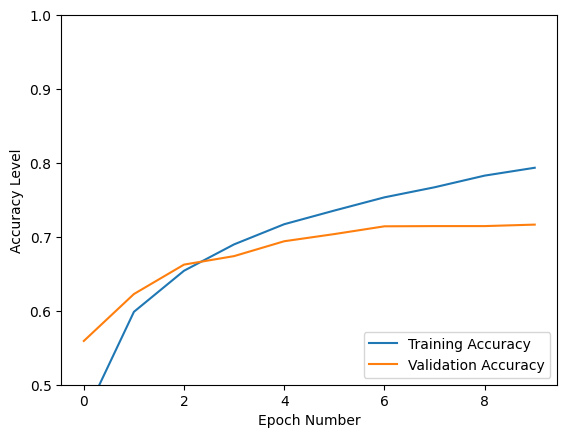

313/313 - 3s - loss: 0.8577 - accuracy: 0.7166 - 3s/epoch - 11ms/step
Test Accuracy: 0.7166000008583069


In [ ]:
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
import matplotlib.pyplot as plt

# Load and prepare the CIFAR-10 dataset
(training_images, training_labels), (validation_images, validation_labels) = cifar10.load_data()
training_images, validation_images = training_images / 255.0, validation_images / 255.0

# Define class names for CIFAR-10 dataset
category_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Display the first 25 images from the training dataset
plt.figure(figsize=(10,10))
for index in range(25):
    plt.subplot(5, 5, index + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(training_images[index])
    plt.xlabel(category_names[training_labels[index][0]])
plt.show()

# Construct the neural network architecture
neural_network = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu')
])

# Overview of the model's architecture
neural_network.summary()

# Adding the final layers to the neural network
neural_network.add(Flatten())
neural_network.add(Dense(64, activation='relu'))
neural_network.add(Dense(10))

# Final structure of the model
neural_network.summary()

# Compiling the neural network
neural_network.compile(optimizer='adam',
                       loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                       metrics=['accuracy'])

# Training the model on CIFAR-10 dataset
training_process = neural_network.fit(training_images, training_labels, epochs=10, validation_data=(validation_images, validation_labels))

# Plotting training results
plt.plot(training_process.history['accuracy'], label='Training Accuracy')
plt.plot(training_process.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch Number')
plt.ylabel('Accuracy Level')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
plt.show()

# Evaluating the trained model
loss_on_test, accuracy_on_test = neural_network.evaluate(validation_images, validation_labels, verbose=2)
print(f"Test Accuracy: {accuracy_on_test}")


In [ ]:
!git clone https://github.com/pixlrcom/pixlr-api-example.git
!cd pixlr-api-example
!npm install

Cloning into 'pixlr-api-example'...
fatal: could not read Username for 'https://github.com': No such device or address
/bin/bash: line 1: cd: pixlr-api-example: No such file or directory
npm WARN saveError ENOENT: no such file or directory, open '/content/package.json'
npm notice created a lockfile as package-lock.json. You should commit this file.
npm WARN enoent ENOENT: no such file or directory, open '/content/package.json'
npm WARN content No description
npm WARN content No repository field.
npm WARN content No README data
npm WARN content No license field.

up to date in 0.628s
found 0 vulnerabilities



In [ ]:
!npm run dev

npm ERR! code ENOENT
npm ERR! syscall open
npm ERR! path /content/package.json
npm ERR! errno -2
npm ERR! enoent ENOENT: no such file or directory, open '/content/package.json'
npm ERR! enoent This is related to npm not being able to find a file.
npm ERR! enoent 

npm ERR! A complete log of this run can be found in:
npm ERR!     /root/.npm/_logs/2024-02-06T05_38_36_031Z-debug.log


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Load and preprocess the CIFAR-10 dataset
(train_images, train_labels), (test_images, test_labels) = keras.datasets.cifar10.load_data()
train_images, test_images = train_images / 255.0, test_images / 255.0

# Data Augmentation
data_augmentation = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    vertical_flip=False,
    fill_mode='nearest'
)

# Define the CNN model
model = keras.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Train the model with data augmentation
batch_size = 64
epochs = 100

history = model.fit(
    data_augmentation.flow(train_images, train_labels, batch_size=batch_size),
    validation_data=(test_images, test_labels),
    epochs=epochs
)

# Evaluate the model
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(f"Test accuracy: {test_acc}")

# Save the trained model
model.save('cifar10_cnn_model.h5')
